# CDC HDP-proxy · оценка фиксированных и настроенных моделей на пяти общих фолдах

Здесь сначала оцениваются фиксированные модели из 02, затем — внешние прогнозы настроенных моделей из того же ноутбука. Каждая строка оценивается ровно один раз вне своего обучения. Показаны распределения AUROC/AUPRC/Brier, калибровка, чувствительность при **описательном** бюджете верхних 10% прогнозов и сравнение с наблюдаемой частью факторов USPSTF. Для применения к будущему году фиксированный порог получают из 2023 OOF и проверяют в 06.

`calibration_in_the_large` рассчитывается с наклоном логита, фиксированным равным 1; калибровочный наклон оценивается отдельно. Правило USPSTF частичное: прежняя ПЭ, почечная/аутоиммунная болезнь, семейный анамнез и др. отсутствуют. Неизвестные измеренные факторы не превращаются в отсутствие риска.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/data/preeclampsia_cdc.py").exists())
sys.path.insert(0, str(ROOT))
from src.progress import tqdm
plt.rcParams.update({"figure.figsize": (8, 4.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2})
BLUE, ORANGE, GREY = "#255B8B", "#D17A31", "#666D78"
MODEL_PALETTE = [("logistic_spline", BLUE), ("hist_gb", ORANGE),
                 ("catboost", "#287D69"), ("lightgbm", "#8062A5")]
RACE6 = {1:"White",2:"Black",3:"AIAN",4:"Asian",5:"NHOPI",6:"Multiple"}  # NCHS MRACE6; social reporting categories
from src.data.preeclampsia_cdc import OUT
from src.training.preeclampsia_cdc import MODEL_NAMES, metrics
from src.evaluation.preeclampsia_cdc import validate_and_summarize, year_breakdown, compare_guideline_at_budget, secondary_outcome_metrics, calibration_offset
from sklearn.calibration import calibration_curve
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

In [2]:
fold_metrics, oof = validate_and_summarize()
display(fold_metrics.round(4))
spread = fold_metrics.groupby("model")[["auroc", "auprc", "brier"]].agg(["mean", "std", "min", "max"])
display(spread.round(4))

Evaluate pooled held-out folds:   0%|          | 0/5 [00:00<?, ?fold/s]

,fold,model,n,events,auroc,auprc,brier,log_loss,mean_prediction,prevalence,...,true_positive,false_positive,true_negative,false_negative,sensitivity,specificity,ppv,sensitivity_at_10pct,specificity_at_10pct,ppv_at_10pct
0,0,prevalence,1353273,142657,0.5000,0.1054,0.0943,0.3368,0.1054,0.1054,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,logistic,1353273,142657,0.6570,0.1894,0.0912,0.3218,0.1054,0.1054,...,31685.0,103643.0,1106973.0,110972.0,0.2221,0.9144,0.2341,0.2221,0.9144,0.2341
2,0,logistic_spline,1353273,142657,0.6637,0.1921,0.0909,0.3204,0.1055,0.1054,...,32009.0,103319.0,1107297.0,110648.0,0.2244,0.9147,0.2365,0.2244,0.9147,0.2365
3,0,hist_gb,1353273,142657,0.6658,0.1932,0.0908,0.3199,0.1054,0.1054,...,32172.0,103156.0,1107460.0,110485.0,0.2255,0.9148,0.2377,0.2255,0.9148,0.2377
4,0,catboost,1353273,142657,0.6659,0.1940,0.0908,0.3198,0.1054,0.1054,...,32194.0,103134.0,1107482.0,110463.0,0.2257,0.9148,0.2379,0.2257,0.9148,0.2379
5,0,lightgbm,1353273,142657,0.6660,0.1936,0.0908,0.3198,0.1054,0.1054,...,32162.0,103166.0,1107450.0,110495.0,0.2254,0.9148,0.2377,0.2254,0.9148,0.2377
6,1,prevalence,1354005,142970,0.5000,0.1056,0.0944,0.3372,0.1054,0.1056,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1,logistic,1354005,142970,0.6570,0.1887,0.0914,0.3223,0.1053,0.1056,...,31339.0,104062.0,1106973.0,111631.0,0.2192,0.9141,0.2315,0.2192,0.9141,0.2315
8,1,logistic_spline,1354005,142970,0.6631,0.1915,0.0911,0.3209,0.1054,0.1056,...,31668.0,103733.0,1107302.0,111302.0,0.2215,0.9143,0.2339,0.2215,0.9143,0.2339
9,1,hist_gb,1354005,142970,0.6651,0.1926,0.0910,0.3204,0.1054,0.1056,...,31939.0,103462.0,1107573.0,111031.0,0.2234,0.9146,0.2359,0.2234,0.9146,0.2359


auroc                           auprc                  \
                   mean     std     min     max    mean     std     min   
model                                                                     
catboost         0.6655  0.0005  0.6649  0.6661  0.1934  0.0007  0.1924   
hist_gb          0.6654  0.0005  0.6647  0.6661  0.1927  0.0005  0.1918   
lightgbm         0.6656  0.0005  0.6649  0.6662  0.1930  0.0005  0.1922   
logistic         0.6570  0.0003  0.6567  0.6574  0.1888  0.0006  0.1882   
logistic_spline  0.6634  0.0005  0.6628  0.6641  0.1916  0.0006  0.1907   
prevalence       0.5000  0.0000  0.5000  0.5000  0.1054  0.0001  0.1052   

                          brier                          
                    max    mean     std     min     max  
model                                                    
catboost         0.1940  0.0908  0.0001  0.0907  0.0910  
hist_gb          0.1932  0.0908  0.0001  0.0907  0.0910  
lightgbm         0.1936  0.0908  0.0001  0.0907  0.0910  
logistic         0.1894  0.0912  0.0001  0.0911  0.0914  
logistic_spline  0.1921  0.0909  0.0001  0.0908  0.0911  
prevalence       0.1056  0.0943  0.0001  0.0942  0.0944

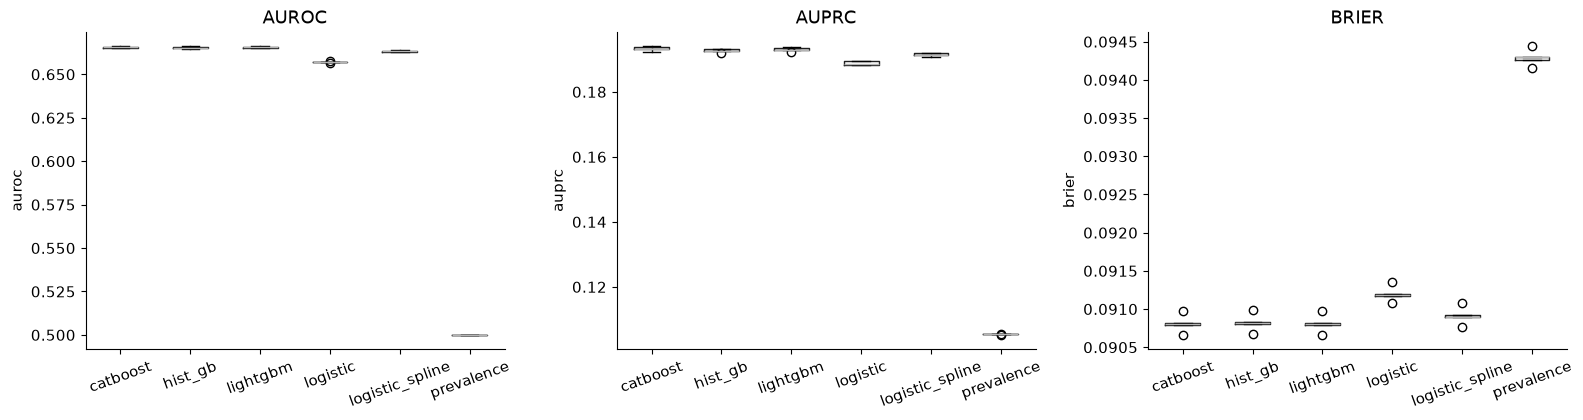

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, ["auroc", "auprc", "brier"]):
    fold_metrics.boxplot(column=metric, by="model", ax=ax, grid=False)
    ax.set(title=metric.upper(), xlabel="", ylabel=metric); ax.tick_params(axis="x", rotation=20)
plt.suptitle(""); plt.tight_layout(); plt.show()

## ROC/PR на случайной выборке 300 000 записей; численные метрики и калибровка — на всех OOF-записях

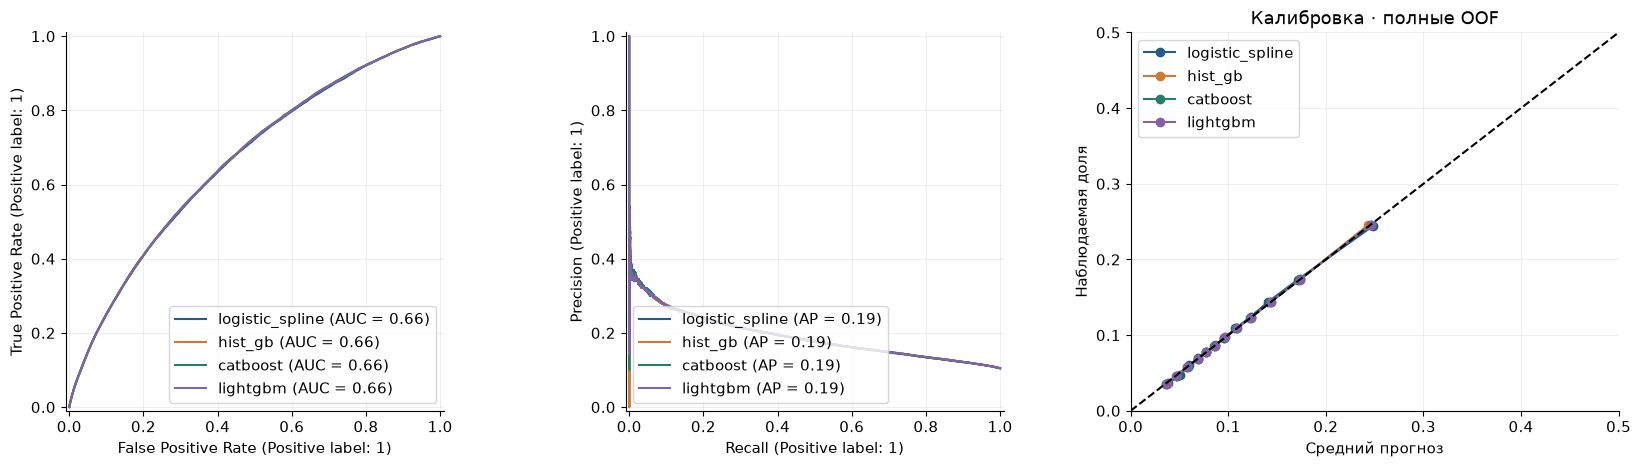

In [4]:
plot_sample = oof.sample(n=min(300_000, len(oof)), random_state=20261001)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for name, color in MODEL_PALETTE:
    RocCurveDisplay.from_predictions(plot_sample.label, plot_sample[name], ax=axes[0], name=name, curve_kwargs={"color": color})
    PrecisionRecallDisplay.from_predictions(plot_sample.label, plot_sample[name], ax=axes[1], name=name, curve_kwargs={"color": color})
    obs, pred = calibration_curve(oof.label, oof[name], n_bins=12, strategy="quantile")
    axes[2].plot(pred, obs, marker="o", label=name, color=color)
axes[2].plot([0,.5],[0,.5],"k--")
axes[2].set(xlim=(0,.5),ylim=(0,.5),xlabel="Средний прогноз",ylabel="Наблюдаемая доля",title="Калибровка · полные OOF")
axes[2].legend(); plt.tight_layout(); plt.show()

## Годы, вторичные сочетания исходов и правило

In [5]:
by_year = year_breakdown(oof)
display(by_year.round(4))
secondary = secondary_outcome_metrics(oof, MODEL_NAMES[1:])
secondary.to_csv(OUT / "pooled_cv_secondary_outcomes.csv", index=False)
display(secondary.round(4))
rule = compare_guideline_at_budget(oof)
rule.to_csv(OUT / "pooled_cv_guideline_comparison.csv", index=False)
display(rule.round(4))

Metrics by year:   0%|          | 0/2 [00:00<?, ?year/s]

,year,model,n,events,auroc,auprc,brier,log_loss,mean_prediction,prevalence
0,2023,prevalence,3369714,348956,0.4994,0.1034,0.0928,0.3328,0.1054,0.1036
1,2023,logistic,3369714,348956,0.6583,0.1864,0.0898,0.3179,0.1051,0.1036
2,2023,logistic_spline,3369714,348956,0.6650,0.1892,0.0895,0.3165,0.1052,0.1036
3,2023,hist_gb,3369714,348956,0.6669,0.1904,0.0894,0.3160,0.1051,0.1036
4,2023,catboost,3369714,348956,0.6670,0.1910,0.0894,0.3160,0.1051,0.1036
5,2023,lightgbm,3369714,348956,0.6671,0.1908,0.0894,0.3160,0.1051,0.1036
6,2024,prevalence,3394136,363962,0.4999,0.1072,0.0957,0.3407,0.1054,0.1072
7,2024,logistic,3394136,363962,0.6557,0.1911,0.0926,0.3257,0.1056,0.1072
8,2024,logistic_spline,3394136,363962,0.6618,0.1938,0.0923,0.3244,0.1057,0.1072
9,2024,hist_gb,3394136,363962,0.6638,0.1950,0.0922,0.3239,0.1057,0.1072


,outcome,model,n,events,auroc,auprc
0,target_hdp_preterm37,logistic,6760254,128857,0.6654,0.0435
1,target_hdp_preterm37,logistic_spline,6760254,128857,0.6788,0.0462
2,target_hdp_preterm37,hist_gb,6760254,128857,0.6820,0.0467
3,target_hdp_preterm37,catboost,6760254,128857,0.6824,0.0472
4,target_hdp_preterm37,lightgbm,6760254,128857,0.6825,0.0471
5,target_hdp_preterm34,logistic,6760254,32368,0.6652,0.0109
6,target_hdp_preterm34,logistic_spline,6760254,32368,0.6793,0.0118
7,target_hdp_preterm34,hist_gb,6760254,32368,0.6830,0.0119
8,target_hdp_preterm34,catboost,6760254,32368,0.6837,0.0121
9,target_hdp_preterm34,lightgbm,6760254,32368,0.6837,0.0121


,model,rule_variant,n,coverage,alert_budget,cases_per_1000,captured_per_1000,flagged_fraction,true_positive,false_positive,true_negative,false_negative,sensitivity,specificity,ppv
0,observed_guideline_subset,core_preconception,6680228,0.9876,0.201,105.3362,36.4815,0.201,243705,1098722,4877836,459965,0.3463,0.8162,0.1815
1,hist_gb,core_preconception,6680228,0.9876,0.201,105.3362,40.2753,0.201,269048,1073379,4903179,434622,0.3823,0.8204,0.2004


## Калибровка по группам, включая отсутствие измеренного фактора высокого риска

Subgroup calibration:   0%|          | 0/28 [00:00<?, ?group/s]

,group,model,n,events,auroc,auprc,brier,log_loss,mean_prediction,prevalence,calibration_in_the_large,mean_calibration_gap_pp
0,no_recorded_pregestational_diabetes,logistic_spline,6692523,695348,0.6605,0.1855,0.0900,0.3181,0.1039,0.1039,0.0002,0.0018
1,no_recorded_pregestational_diabetes,hist_gb,6692523,695348,0.6624,0.1866,0.0899,0.3177,0.1039,0.1039,-0.0006,-0.0050
2,no_recorded_pregestational_diabetes,catboost,6692523,695348,0.6626,0.1872,0.0899,0.3176,0.1039,0.1039,-0.0000,-0.0001
3,no_recorded_pregestational_diabetes,lightgbm,6692523,695348,0.6626,0.1869,0.0899,0.3176,0.1039,0.1039,-0.0001,-0.0009
4,pregestational_diabetes,logistic_spline,71327,17570,0.6250,0.3371,0.1800,0.5423,0.2498,0.2463,-0.0200,-0.3497
...,...,...,...,...,...,...,...,...,...,...,...,...
107,ethnicity_code_5,lightgbm,251460,22981,0.6520,0.1625,0.0811,0.2948,0.1085,0.0914,-0.1965,-1.7080
108,ethnicity_code_9,logistic_spline,62274,5897,0.6598,0.1760,0.0830,0.2990,0.1019,0.0947,-0.0844,-0.7240
109,ethnicity_code_9,hist_gb,62274,5897,0.6617,0.1758,0.0830,0.2988,0.1017,0.0947,-0.0818,-0.7020
110,ethnicity_code_9,catboost,62274,5897,0.6621,0.1770,0.0829,0.2987,0.1016,0.0947,-0.0809,-0.6933


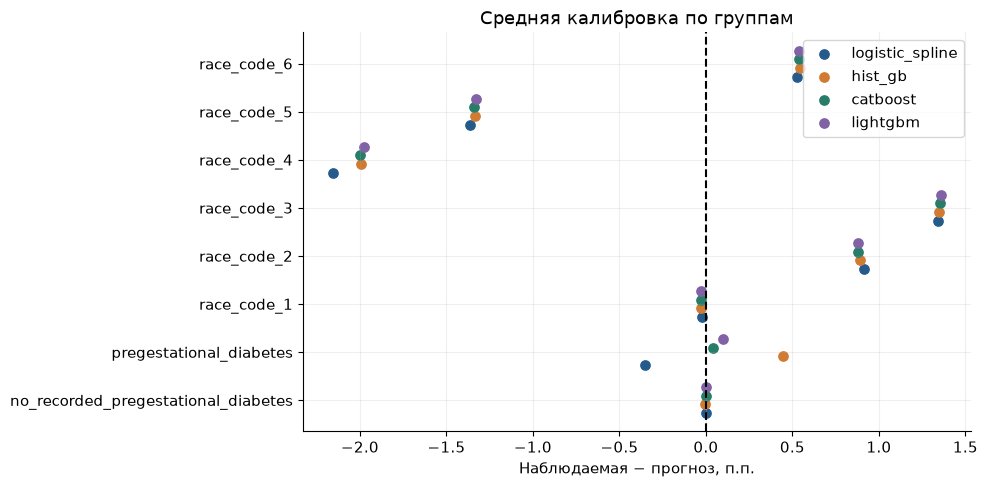

In [6]:
groups = {"no_recorded_pregestational_diabetes": oof.rf_pdiab.eq(0), "pregestational_diabetes": oof.rf_pdiab.eq(1), "bmi_under_30": oof.bmi.lt(30), "bmi_30_plus": oof.bmi.ge(30)}
groups.update({f"{name}_yes":oof[name].eq(1) for name in ["bmi_missing","prior_live_birth_count_missing","priorterm_missing"]})
groups.update({f"race_code_{int(code)}": oof.mrace6.eq(code) for code in sorted(oof.mrace6.dropna().unique())})
groups.update({f"education_code_{int(code)}": oof.meduc.eq(code) for code in sorted(oof.meduc.dropna().unique())})
groups.update({f"ethnicity_code_{int(code)}": oof.mhisp_r.eq(code) for code in sorted(oof.mhisp_r.dropna().unique())})
sub = []
for group, mask in tqdm(groups.items(), desc="Subgroup calibration", unit="group"):
    part = oof.loc[mask]
    if len(part) < 100 or part.label.nunique() < 2: continue
    for name in [model for model,_ in MODEL_PALETTE]:
        sub.append({"group":group,"model":name,"n":len(part),"events":int(part.label.sum()),**metrics(part.label.to_numpy(), part[name].to_numpy()),"calibration_in_the_large":calibration_offset(part.label.to_numpy(),part[name].to_numpy()),"mean_calibration_gap_pp":100*(part.label.mean()-part[name].mean())})
sub = pd.DataFrame(sub)
sub.to_csv(OUT / "pooled_cv_subgroups.csv", index=False)
display(sub.round(4))
selected=sub.loc[sub.group.str.startswith("race_code_")|sub.group.str.contains("diabetes")]
group_order=sorted(selected.group.unique())
fig,ax=plt.subplots(figsize=(10,max(5,.55*len(group_order))))
for offset,(name,color) in zip(np.linspace(-.27,.27,len(MODEL_PALETTE)),MODEL_PALETTE):
    part=selected.loc[selected.model.eq(name)].set_index("group").reindex(group_order)
    ax.scatter(part.mean_calibration_gap_pp,np.arange(len(group_order))+offset,label=name,color=color,s=45)
ax.axvline(0,color="black",ls="--"); ax.set_yticks(np.arange(len(group_order)),group_order)
ax.set(xlabel="Наблюдаемая − прогноз, п.п.",title="Средняя калибровка по группам")
ax.legend(); plt.tight_layout(); plt.show()

## Аудит импутации расы на тех же отложенных прогнозах

Флаг `MRACEIMP` восстановлен из исходных CSV в отдельной таблице по `source_year, source_row`. Он нужен только для аудита и не входит во вход модели. Таблица сверяется с опубликованным кодом `MRACE6` и агрегированным аудитом 01. Разрывы калибровки показаны по опубликованной расе отдельно до и после исключения записей с импутацией.

,year,race_code,subset,model,n,events,event_rate,mean_prediction,mean_calibration_gap_pp
1,2023,1,all,hist_gb,2503289,256572,0.1025,0.1044,-0.1875
5,2023,1,non_imputed,hist_gb,2280736,239024,0.1048,0.1045,0.0296
9,2023,1,imputed,hist_gb,222553,17548,0.0788,0.1030,-2.4128
13,2023,2,all,hist_gb,502654,60648,0.1207,0.1139,0.6797
17,2023,2,non_imputed,hist_gb,466987,57703,0.1236,0.1144,0.9129
21,2023,2,imputed,hist_gb,35667,2945,0.0826,0.1063,-2.3733
25,2023,3,all,hist_gb,32888,4051,0.1232,0.1104,1.2764
29,2023,3,non_imputed,hist_gb,28681,3689,0.1286,0.1115,1.7140
33,2023,3,imputed,hist_gb,4207,362,0.0860,0.1031,-1.7072
37,2023,4,all,hist_gb,218734,15394,0.0704,0.0909,-2.0549


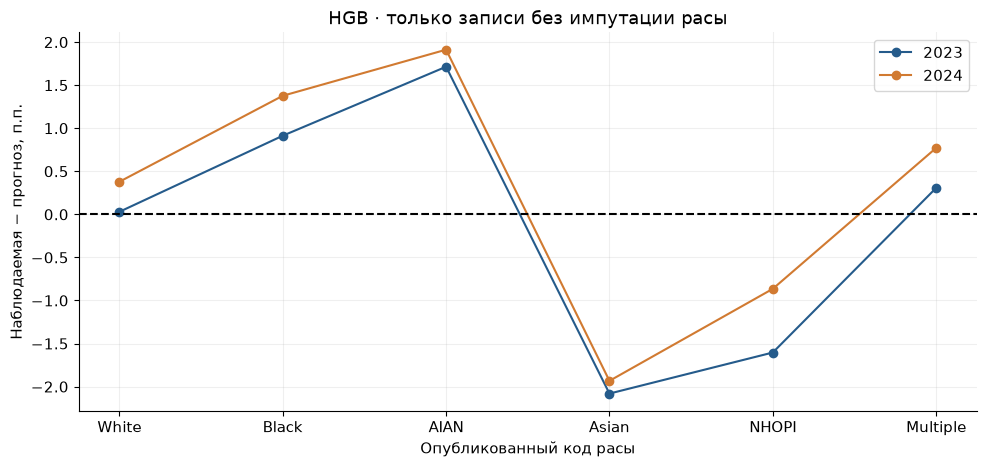

In [7]:
from src.evaluation.preeclampsia_cdc_race import build_race_imputation_rows, race_imputation_sensitivity, RACE_ROWS
if not RACE_ROWS.exists():
    build_race_imputation_rows()
race_sensitivity = race_imputation_sensitivity(oof, ["logistic_spline", "hist_gb", "catboost", "lightgbm"])
race_sensitivity.to_csv(OUT / "pooled_cv_race_imputation_sensitivity.csv", index=False)
display(race_sensitivity.loc[race_sensitivity.model.eq("hist_gb")].round(4))
non_imputed = race_sensitivity.loc[race_sensitivity.subset.eq("non_imputed") & race_sensitivity.model.eq("hist_gb")]
fig, ax = plt.subplots(figsize=(10, 4.8))
for year, color in [(2023, BLUE), (2024, ORANGE)]:
    part = non_imputed.loc[non_imputed.year.eq(year)].sort_values("race_code")
    ax.plot(part.race_code, part.mean_calibration_gap_pp, marker="o", label=str(year), color=color)
ax.axhline(0, color="black", ls="--")
ax.set_xticks(range(1, 7), [RACE6[n] for n in range(1, 7)])
ax.set(xlabel="Опубликованный код расы", ylabel="Наблюдаемая − прогноз, п.п.",
       title="HGB · только записи без импутации расы")
ax.legend(); plt.tight_layout(); plt.show()

## Ограничения

Это качество прогнозирования записанного HDP-proxy, не клинический риск ПЭ. Факторы анамнеза и метка заполняются в одном свидетельстве, поэтому ошибки их регистрации могут быть связаны. Пропущенный BMI может отражать процесс заполнения; его связь с меткой не доказывает причину. Раса в записи не биологический механизм и может отражать социальное неравенство/качество кодировки; сравнение групп обязательно интерпретировать с этой оговоркой. Отдельный флаг импутации позволяет проверить устойчивость групповых результатов, но исключение импутированных строк не делает расу биологическим предиктором. Если обнаружится недооценка или переоценка по группе, сначала нужно проверить качество регистрации исхода и перенос; групповую коррекцию по тем же меткам автоматически не обучаем. Одна женщина может встретиться в обоих годах; идентификатора нет. В исследовании нет мертворождений. Для проверок переноса и фиксированного порога используйте 06.

## Внешняя оценка настроенной процедуры · все записи 2023+2024

Раздел читает и проверяет сохранённые прогнозы из 02. **Обучения и подбора здесь нет.** Внешние метки каждого фолда не использовались для выбора параметров этого фолда. Для вывода показаны распределения, стабильность выбора, ROC/PR, калибровка и разрезы. Оба года перемешаны во внешних фолдах: разбивка по году не является проверкой переноса.

In [8]:
import gc
for old_name in ("oof", "plot_sample", "sub", "groups"):
    globals().pop(old_name, None)
gc.collect()
from src.training.preeclampsia_cdc_nested import NESTED_DIR, load_nested_results
from src.training.preeclampsia_cdc_final import FINAL_DIR, load_full_cohort_best
inner_nested, outer_nested, choices_nested, oof_nested = load_nested_results()
pooled_nested = pd.read_csv(NESTED_DIR / "pooled_metrics.csv")
print("Внутренних проверок:", len(inner_nested), "· внешних оценок:", len(outer_nested))
print("Внешних OOF-прогнозов:", f"{len(oof_nested):,}")
display(choices_nested)
display(pooled_nested.round(5))

Внутренних проверок: 440 · внешних оценок: 35
Внешних OOF-прогнозов: 6,763,850


,outer_fold,overall_winner,prevalence_candidate_id,logistic_candidate_id,logistic_spline_candidate_id,hist_gb_candidate_id,catboost_candidate_id,lightgbm_candidate_id
0,0,catboost,7e05976576b2,98aeddc3133d,247cce42f0e8,8b9b7a3ca540,08d1effab5f7,c50553e3d039
1,1,catboost,7e05976576b2,98aeddc3133d,247cce42f0e8,8b9b7a3ca540,97a167526785,c50553e3d039
2,2,catboost,7e05976576b2,98aeddc3133d,247cce42f0e8,8b9b7a3ca540,08d1effab5f7,c50553e3d039
3,3,catboost,7e05976576b2,98aeddc3133d,247cce42f0e8,28fde1366938,08d1effab5f7,1f7e1bceccdd
4,4,catboost,7e05976576b2,98aeddc3133d,247cce42f0e8,8b9b7a3ca540,97a167526785,c50553e3d039


,model,n,events,auroc,auprc,brier,log_loss,mean_prediction,prevalence
0,prevalence,6763850,712918,0.49967,0.10532,0.09429,0.33679,0.10540,0.1054
1,logistic,6763850,712918,0.65699,0.18877,0.09120,0.32184,0.10534,0.1054
2,logistic_spline,6763850,712918,0.66342,0.19154,0.09092,0.32042,0.10542,0.1054
3,hist_gb,6763850,712918,0.66538,0.19272,0.09083,0.31999,0.10540,0.1054
4,catboost,6763850,712918,0.66552,0.19335,0.09081,0.31993,0.10540,0.1054
5,lightgbm,6763850,712918,0.66556,0.19306,0.09081,0.31994,0.10540,0.1054
6,selected,6763850,712918,0.66552,0.19335,0.09081,0.31993,0.10540,0.1054


## Распределение внешних метрик

Каждая точка — один внешний фолд. Строка `selected` отражает **полную процедуру выбора типа модели и параметров внутри фолда**; в разных внешних фолдах тип модели может различаться. Пять точек показывают устойчивость к разделению, но не являются независимыми пациентами или доверительным интервалом.

,outer_fold,model,candidate_id,n,events,auroc,auprc,brier,log_loss
4,0,catboost,08d1effab5f7,1353273,142657,0.66589,0.19405,0.09079,0.31985
11,1,catboost,97a167526785,1354005,142970,0.66515,0.19336,0.09097,0.32040
18,2,catboost,08d1effab5f7,1352650,142580,0.66546,0.19390,0.09080,0.31992
25,3,catboost,08d1effab5f7,1351623,142420,0.66495,0.19235,0.09082,0.32000
32,4,catboost,97a167526785,1352299,142291,0.66616,0.19322,0.09066,0.31950
3,0,hist_gb,8b9b7a3ca540,1353273,142657,0.66575,0.19324,0.09081,0.31991
10,1,hist_gb,8b9b7a3ca540,1354005,142970,0.66508,0.19262,0.09099,0.32045
17,2,hist_gb,8b9b7a3ca540,1352650,142580,0.66535,0.19308,0.09082,0.31998
24,3,hist_gb,28fde1366938,1351623,142420,0.66474,0.19185,0.09083,0.32006
31,4,hist_gb,8b9b7a3ca540,1352299,142291,0.66604,0.19268,0.09067,0.31955


auroc                               auprc           \
                    mean      std      min      max     mean      std   
model                                                                   
catboost         0.66552  0.00051  0.66495  0.66616  0.19337  0.00067   
hist_gb          0.66539  0.00052  0.66474  0.66604  0.19269  0.00054   
lightgbm         0.66557  0.00052  0.66494  0.66621  0.19306  0.00055   
logistic         0.65699  0.00027  0.65668  0.65742  0.18879  0.00058   
logistic_spline  0.66342  0.00050  0.66279  0.66407  0.19155  0.00056   
prevalence       0.50000  0.00000  0.50000  0.50000  0.10540  0.00013   
selected         0.66552  0.00051  0.66495  0.66616  0.19337  0.00067   

                                     brier                             \
                     min      max     mean      std      min      max   
model                                                                   
catboost         0.19235  0.19405  0.09081  0.00011  0.09066  0.09097   
hist_gb          0.19185  0.19324  0.09083  0.00011  0.09067  0.09099   
lightgbm         0.19221  0.19365  0.09081  0.00011  0.09066  0.09097   
logistic         0.18816  0.18939  0.09120  0.00010  0.09107  0.09136   
logistic_spline  0.19072  0.19208  0.09092  0.00011  0.09077  0.09108   
prevalence       0.10522  0.10559  0.09429  0.00010  0.09415  0.09444   
selected         0.19235  0.19405  0.09081  0.00011  0.09066  0.09097   

                log_loss                             
                    mean      std      min      max  
model                                                
catboost         0.31993  0.00032  0.31950  0.32040  
hist_gb          0.31999  0.00032  0.31955  0.32045  
lightgbm         0.31994  0.00032  0.31950  0.32040  
logistic         0.32184  0.00029  0.32148  0.32228  
logistic_spline  0.32042  0.00032  0.31998  0.32089  
prevalence       0.33679  0.00028  0.33641  0.33720  
selected         0.31993  0.00032  0.31950  0.32040

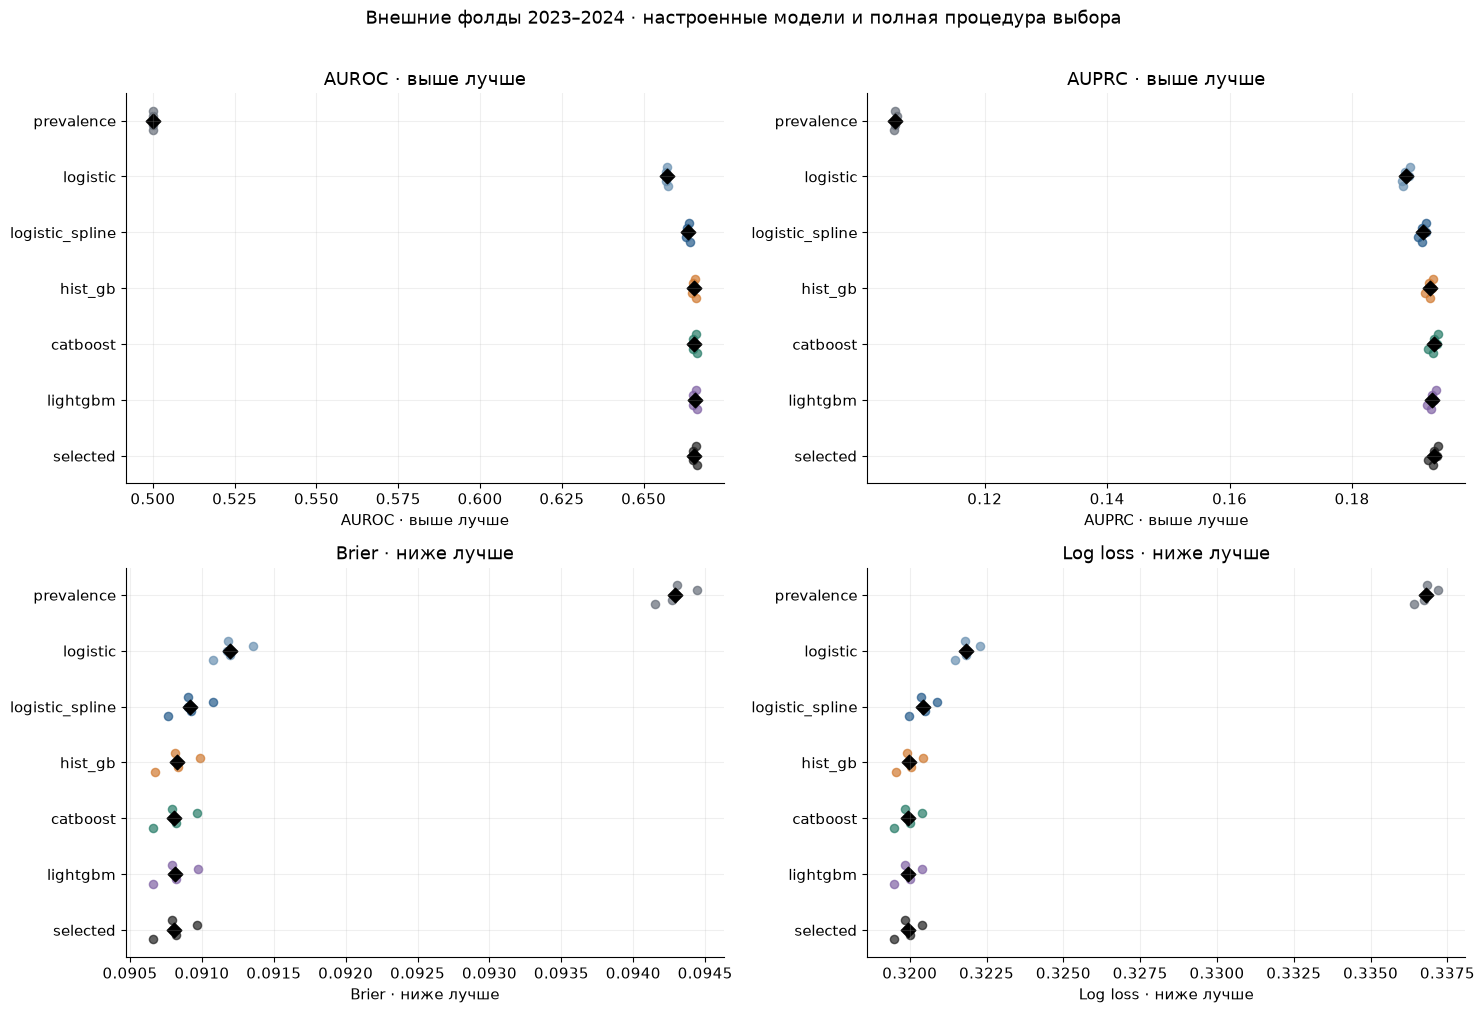

In [9]:
plot_models = MODEL_NAMES + ["selected"]
palette = {"prevalence": GREY, "logistic": "#6A91B1", **dict(MODEL_PALETTE), "selected": "#202020"}
display(outer_nested[["outer_fold", "model", "candidate_id", "n", "events", "auroc", "auprc", "brier", "log_loss"]]
        .sort_values(["model", "outer_fold"]).round(5))
spread_nested = outer_nested.groupby("model")[["auroc", "auprc", "brier", "log_loss"]].agg(["mean", "std", "min", "max"])
display(spread_nested.round(5))
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, metric, title in zip(axes.flat, ["auroc", "auprc", "brier", "log_loss"],
                             ["AUROC · выше лучше", "AUPRC · выше лучше", "Brier · ниже лучше", "Log loss · ниже лучше"]):
    for position, name in enumerate(plot_models):
        part = outer_nested.loc[outer_nested.model.eq(name)].sort_values("outer_fold")
        assert part.outer_fold.tolist() == list(range(5))
        ax.scatter(part[metric], position + np.linspace(-.17, .17, 5), color=palette[name], alpha=.7, s=35)
        ax.scatter(part[metric].mean(), position, marker="D", color="black", s=55)
    ax.set_yticks(range(len(plot_models)), plot_models)
    ax.invert_yaxis()
    ax.set(xlabel=title, title=title)
fig.suptitle("Внешние фолды 2023–2024 · настроенные модели и полная процедура выбора", y=1.01)
plt.tight_layout(); plt.show()

## Стабильность выбранных параметров и разрыв внутренней/внешней оценки

Частоты выбранных конфигураций и типов моделей помогают увидеть нестабильный выбор. Внутренний и внешний `log loss` получены на разных записях и при разном размере обучающей части; их разность описательна и **не является чистой оценкой переобучения**.

,model,candidate_id,params_json,outer_folds
0,catboost,08d1effab5f7,"{""depth"": 5, ""l2_leaf_reg"": 8.0}",3
1,catboost,97a167526785,"{""depth"": 5, ""l2_leaf_reg"": 3.0}",2
3,hist_gb,8b9b7a3ca540,"{""l2_regularization"": 1.0, ""max_leaf_nodes"": 15}",4
2,hist_gb,28fde1366938,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 15}",1
5,lightgbm,c50553e3d039,"{""min_child_samples"": 500, ""num_leaves"": 15}",4
4,lightgbm,1f7e1bceccdd,"{""min_child_samples"": 200, ""num_leaves"": 15}",1
6,logistic,98aeddc3133d,"{""C"": 10.0}",5
7,logistic_spline,247cce42f0e8,"{""C"": 3.0, ""n_knots"": 5}",5
8,prevalence,7e05976576b2,{},5


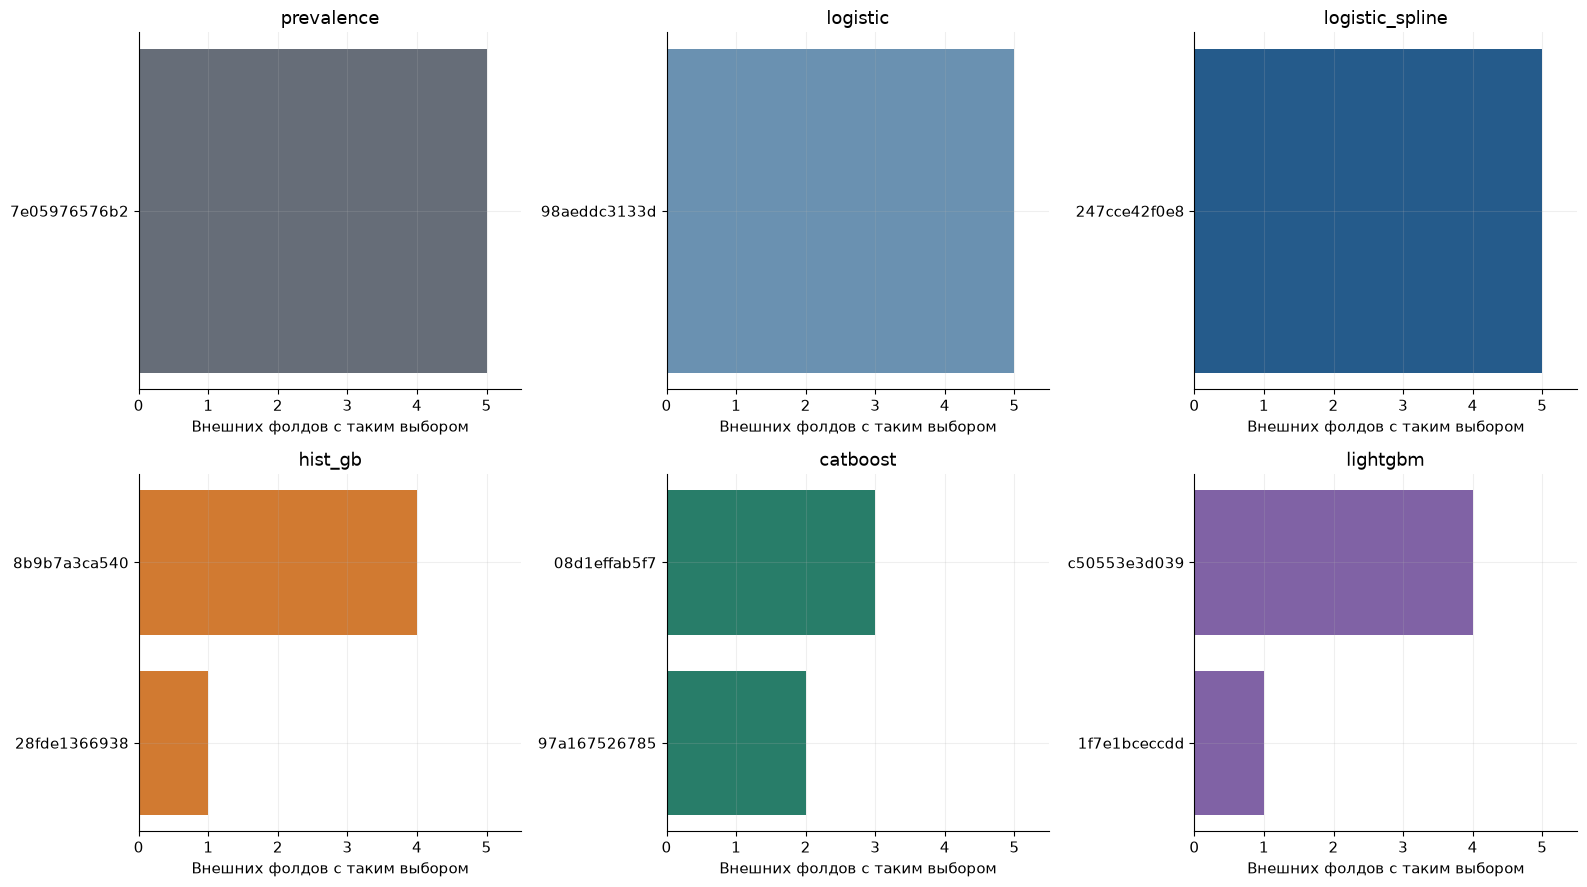

,outer_fold,model,inner_log_loss,outer_log_loss
0,0,catboost,0.31996,0.31985
1,1,catboost,0.31983,0.32040
2,2,catboost,0.31994,0.31992
3,3,catboost,0.31993,0.32000
4,4,catboost,0.32005,0.31950


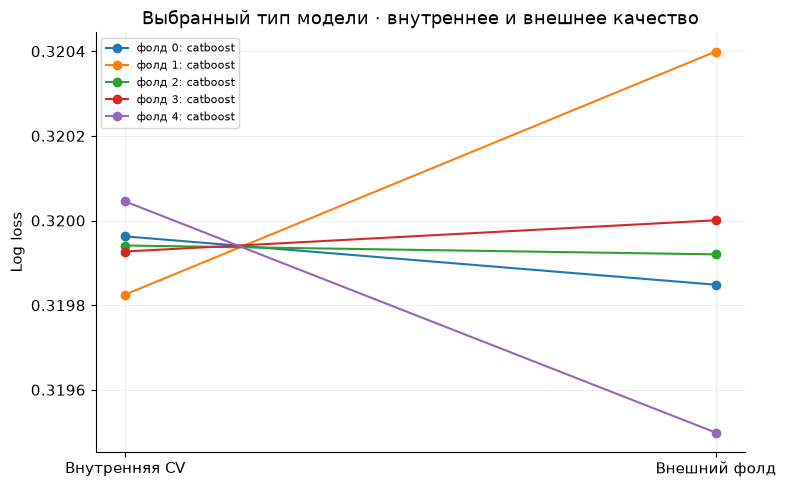

In [10]:
stability = (outer_nested.loc[outer_nested.model.isin(MODEL_NAMES)]
             .groupby(["model", "candidate_id", "params_json"], as_index=False)
             .agg(outer_folds=("outer_fold", "nunique")))
display(stability.sort_values(["model", "outer_folds"], ascending=[True, False]))
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, MODEL_NAMES):
    part = stability.loc[stability.model.eq(name)].sort_values("outer_folds")
    ax.barh(part.candidate_id, part.outer_folds, color=palette[name])
    ax.set(xlim=(0, 5.5), xlabel="Внешних фолдов с таким выбором", title=name)
    ax.set_xticks(range(6))
plt.tight_layout(); plt.show()
selection_diagnostic = []
for choice in choices_nested.itertuples(index=False):
    name = choice.overall_winner
    key = getattr(choice, f"{name}_candidate_id")
    inner_part = inner_nested.loc[inner_nested.outer_fold.eq(choice.outer_fold)
                                  & inner_nested.model.eq(name)
                                  & inner_nested.candidate_id.eq(key)]
    external = outer_nested.loc[outer_nested.outer_fold.eq(choice.outer_fold)
                                & outer_nested.model.eq("selected")].iloc[0]
    assert len(inner_part) == 4
    selection_diagnostic.append({"outer_fold": choice.outer_fold, "model": name,
        "inner_log_loss": np.average(inner_part.log_loss, weights=inner_part.n),
        "outer_log_loss": external.log_loss})
selection_diagnostic = pd.DataFrame(selection_diagnostic)
display(selection_diagnostic.round(5))
fig, ax = plt.subplots(figsize=(8, 5))
for row in selection_diagnostic.itertuples(index=False):
    ax.plot([0, 1], [row.inner_log_loss, row.outer_log_loss], marker="o", label=f"фолд {row.outer_fold}: {row.model}")
ax.set_xticks([0, 1], ["Внутренняя CV", "Внешний фолд"])
ax.set(ylabel="Log loss", title="Выбранный тип модели · внутреннее и внешнее качество")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## ROC, PR и калибровка внешних прогнозов

Численные метрики в таблице выше и калибровка ниже считаются по **всем** отложенным записям. Для читаемых ROC/PR-кривых используется случайная выборка до 300 000 записей; их подписи относятся только к этой выборке. Чёрная линия — процедура выбора (`selected`), остальные — каждая семья моделей с собственным внутренним подбором.

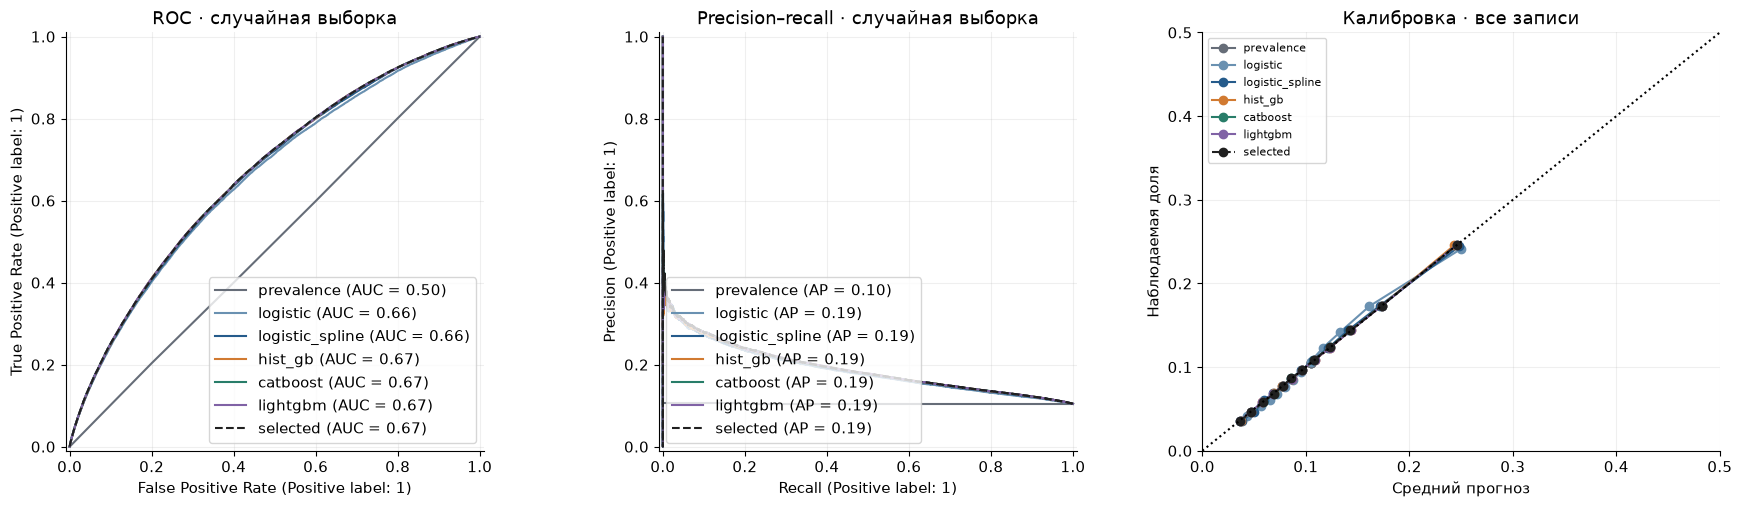

In [11]:
plot_sample = oof_nested.sample(n=min(300_000, len(oof_nested)), random_state=20261001)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for name in plot_models:
    style = {"color": palette[name], "linestyle": "--" if name == "selected" else "-"}
    RocCurveDisplay.from_predictions(plot_sample.label, plot_sample[name], ax=axes[0], name=name, curve_kwargs=style)
    PrecisionRecallDisplay.from_predictions(plot_sample.label, plot_sample[name], ax=axes[1], name=name, curve_kwargs=style)
    observed, predicted = calibration_curve(oof_nested.label, oof_nested[name], n_bins=12, strategy="quantile")
    axes[2].plot(predicted, observed, marker="o", label=name, **style)
axes[2].plot([0, .5], [0, .5], "k:")
axes[0].set(title="ROC · случайная выборка")
axes[1].set(title="Precision–recall · случайная выборка")
axes[2].set(xlim=(0, .5), ylim=(0, .5), xlabel="Средний прогноз", ylabel="Наблюдаемая доля", title="Калибровка · все записи")
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Разбивка внешних прогнозов по году

Здесь фолды смешанные: модели для записей 2023 могут обучаться на части 2024, и наоборот. Поэтому эта таблица описывает неоднородность внутри вложенной оценки, **не** перенос 2023→2024. Для направленной проверки используйте ноутбук 06.

,year,model,n,events,auroc,auprc,brier,log_loss,mean_prediction,prevalence
0,2023,prevalence,3369714,348956,0.49939,0.10340,0.09284,0.33285,0.10540,0.10356
1,2023,logistic,3369714,348956,0.65830,0.18644,0.08979,0.31792,0.10509,0.10356
2,2023,logistic_spline,3369714,348956,0.66501,0.18924,0.08951,0.31645,0.10516,0.10356
3,2023,hist_gb,3369714,348956,0.66695,0.19045,0.08942,0.31603,0.10512,0.10356
4,2023,catboost,3369714,348956,0.66706,0.19099,0.08940,0.31598,0.10511,0.10356
5,2023,lightgbm,3369714,348956,0.66711,0.19077,0.08941,0.31597,0.10511,0.10356
6,2023,selected,3369714,348956,0.66706,0.19099,0.08940,0.31598,0.10511,0.10356
7,2024,prevalence,3394136,363962,0.49993,0.10723,0.09574,0.34071,0.10540,0.10723
8,2024,logistic,3394136,363962,0.65568,0.19105,0.09259,0.32573,0.10559,0.10723
9,2024,logistic_spline,3394136,363962,0.66185,0.19382,0.09231,0.32435,0.10568,0.10723


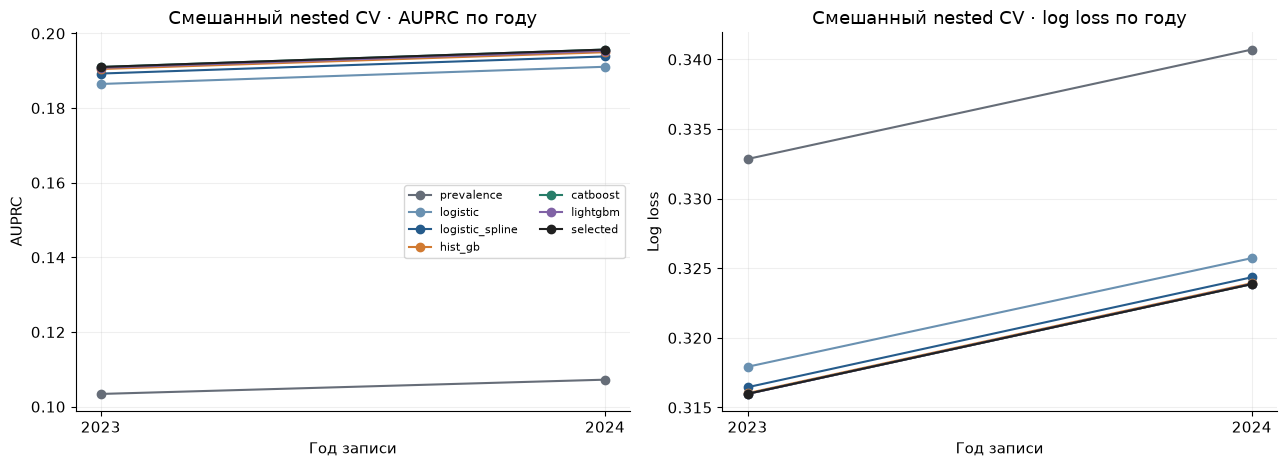

In [12]:
year_rows = []
for year, part in oof_nested.groupby("source_year", sort=True):
    for name in plot_models:
        year_rows.append({"year": int(year), "model": name, "n": len(part),
            "events": int(part.label.sum()), **metrics(part.label.to_numpy(), part[name].to_numpy())})
year_nested = pd.DataFrame(year_rows)
year_nested.to_csv(NESTED_DIR / "metrics_by_year.csv", index=False)
display(year_nested.round(5))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name in plot_models:
    part = year_nested.loc[year_nested.model.eq(name)].sort_values("year")
    axes[0].plot(part.year, part.auprc, marker="o", label=name, color=palette[name])
    axes[1].plot(part.year, part.log_loss, marker="o", label=name, color=palette[name])
axes[0].set(ylabel="AUPRC", title="Смешанный nested CV · AUPRC по году")
axes[1].set(ylabel="Log loss", title="Смешанный nested CV · log loss по году")
for ax in axes:
    ax.set_xticks([2023, 2024])
    ax.set_xlabel("Год записи")
axes[0].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

## Вторичные исходы, частичное правило и подгруппы

Внешние прогнозы настроенных моделей сохраняют вторичные метки и поля аудита. Для сочетаний HDP-proxy с родами до 37/34 недель показывается только **дискриминация**: вероятность HDP-proxy не является калиброванной вероятностью составного исхода. Частичное наблюдаемое правило USPSTF сравнивается при одинаковом числе отмеченных записей; пропущенные клинические факторы не считаются отрицательными. Подгруппы нужны для аудита регистрации и калибровки, а не для биологического объяснения различий.

,outcome,model,n,events,auroc,auprc
0,target_hdp_preterm37,logistic,6760254,128857,0.66537,0.04346
1,target_hdp_preterm37,logistic_spline,6760254,128857,0.67876,0.04620
2,target_hdp_preterm37,hist_gb,6760254,128857,0.68197,0.04669
3,target_hdp_preterm37,catboost,6760254,128857,0.68244,0.04717
4,target_hdp_preterm37,lightgbm,6760254,128857,0.68251,0.04710
5,target_hdp_preterm37,selected,6760254,128857,0.68244,0.04717
6,target_hdp_preterm34,logistic,6760254,32368,0.66517,0.01085
7,target_hdp_preterm34,logistic_spline,6760254,32368,0.67929,0.01179
8,target_hdp_preterm34,hist_gb,6760254,32368,0.68296,0.01191
9,target_hdp_preterm34,catboost,6760254,32368,0.68362,0.01208


,model,rule_variant,n,coverage,alert_budget,cases_per_1000,captured_per_1000,flagged_fraction,true_positive,false_positive,true_negative,false_negative,sensitivity,specificity,ppv
0,observed_guideline_subset,core_preconception,6680228,0.98764,0.20096,105.33623,36.48154,0.20096,243705,1098722,4877836,459965,0.34633,0.81616,0.18154
1,selected,core_preconception,6680228,0.98764,0.20096,105.33623,40.27063,0.20096,269017,1073410,4903148,434653,0.38231,0.82040,0.20040


Nested subgroup audit:   0%|          | 0/10 [00:00<?, ?group/s]

,group,n,events,auroc,auprc,brier,log_loss,mean_prediction,prevalence,mean_calibration_gap_pp
0,diabetes_recorded_yes,71327,17570,0.63309,0.34357,0.17819,0.53767,0.24588,0.24633,0.04477
1,diabetes_recorded_no,6692523,695348,0.66256,0.18719,0.08988,0.31761,0.10390,0.10390,-0.00020
2,bmi_missing,155723,15279,0.60129,0.14101,0.08734,0.31484,0.09649,0.09812,0.16242
3,prior_live_birth_count_missing,19453,1626,0.61065,0.12374,0.07566,0.28157,0.08610,0.08359,-0.25154
4,race_code_1,5034099,525249,0.66822,0.19373,0.08991,0.31723,0.10459,0.10434,-0.02552
5,race_code_2,987360,121829,0.64004,0.20175,0.10509,0.36079,0.11462,0.12339,0.87694
6,race_code_3,65883,8187,0.65094,0.21235,0.10522,0.36015,0.11073,0.12427,1.35406
7,race_code_4,449010,32111,0.66781,0.14149,0.06489,0.24786,0.09149,0.07152,-1.99710
8,race_code_5,26904,2678,0.68530,0.19713,0.08585,0.30530,0.11294,0.09954,-1.34042
9,race_code_6,200594,22864,0.66656,0.20672,0.09705,0.33671,0.10860,0.11398,0.53855


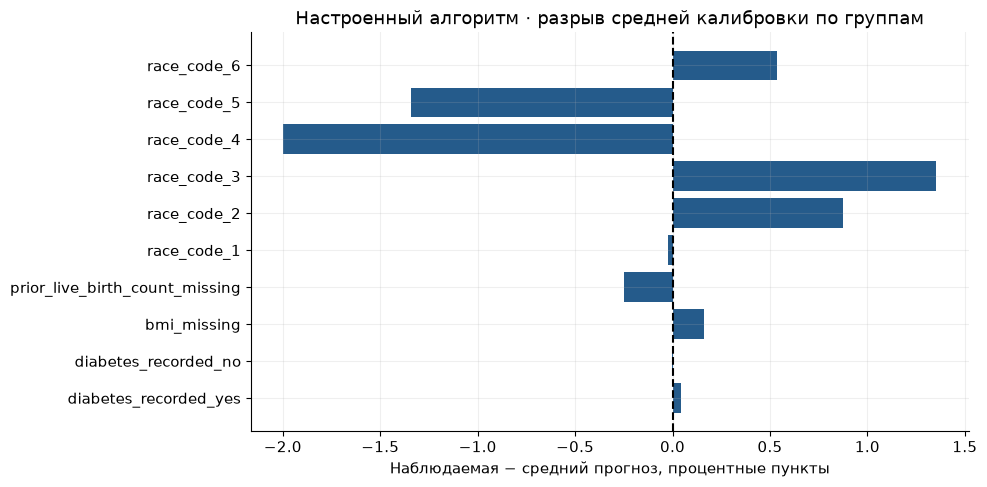

In [13]:
secondary_nested = secondary_outcome_metrics(oof_nested, MODEL_NAMES[1:] + ["selected"])
secondary_nested.to_csv(NESTED_DIR / "secondary_outcome_discrimination.csv", index=False)
display(secondary_nested.round(5))
rule_nested = pd.concat([
    compare_guideline_at_budget(oof_nested, model="selected"),
], ignore_index=True)
rule_nested.to_csv(NESTED_DIR / "guideline_comparison.csv", index=False)
display(rule_nested.round(5))
groups = {"diabetes_recorded_yes": oof_nested.rf_pdiab.eq(1),
          "diabetes_recorded_no": oof_nested.rf_pdiab.eq(0),
          "bmi_missing": oof_nested.bmi_missing.eq(1),
          "prior_live_birth_count_missing": oof_nested.prior_live_birth_count_missing.eq(1)}
groups.update({f"race_code_{int(code)}": oof_nested.mrace6.eq(code)
               for code in sorted(oof_nested.mrace6.dropna().unique())})
subgroup_rows = []
for group, mask in tqdm(groups.items(), desc="Nested subgroup audit", unit="group"):
    part = oof_nested.loc[mask]
    if len(part) < 100 or part.label.nunique() < 2:
        continue
    subgroup_rows.append({"group": group, "n": len(part), "events": int(part.label.sum()),
        **metrics(part.label.to_numpy(), part.selected.to_numpy()),
        "mean_calibration_gap_pp": 100 * (part.label.mean() - part.selected.mean())})
subgroups_nested = pd.DataFrame(subgroup_rows)
subgroups_nested.to_csv(NESTED_DIR / "selected_subgroups.csv", index=False)
display(subgroups_nested.round(5))
fig, ax = plt.subplots(figsize=(10, max(5, .5 * len(subgroups_nested))))
ax.barh(subgroups_nested.group, subgroups_nested.mean_calibration_gap_pp, color=BLUE)
ax.axvline(0, color="black", ls="--")
ax.set(xlabel="Наблюдаемая − средний прогноз, процентные пункты",
       title="Настроенный алгоритм · разрыв средней калибровки по группам")
plt.tight_layout(); plt.show()

## Импутация расы и внешний прогноз настроенной процедуры

Та же строковая проверка выполняется для `selected` после вложенного подбора. Здесь тип модели может различаться по внешним фолдам; исключение импутированных строк меняет состав подгруппы и служит проверкой устойчивости описательного разрыва.

In [14]:
from src.evaluation.preeclampsia_cdc_race import race_imputation_sensitivity
nested_race = race_imputation_sensitivity(oof_nested, ["selected"])
nested_race.to_csv(NESTED_DIR / "selected_race_imputation_sensitivity.csv", index=False)
display(nested_race.round(4))

,year,race_code,subset,model,n,events,event_rate,mean_prediction,mean_calibration_gap_pp
0,2023,1,all,selected,2503289,256572,0.1025,0.1043,-0.1829
1,2023,1,non_imputed,selected,2280736,239024,0.1048,0.1045,0.0336
2,2023,1,imputed,selected,222553,17548,0.0788,0.1029,-2.4016
3,2023,2,all,selected,502654,60648,0.1207,0.1140,0.6636
4,2023,2,non_imputed,selected,466987,57703,0.1236,0.1146,0.8956
5,2023,2,imputed,selected,35667,2945,0.0826,0.1063,-2.3733
6,2023,3,all,selected,32888,4051,0.1232,0.1104,1.2808
7,2023,3,non_imputed,selected,28681,3689,0.1286,0.1114,1.7183
8,2023,3,imputed,selected,4207,362,0.0860,0.1031,-1.7022
9,2023,4,all,selected,218734,15394,0.0704,0.0910,-2.0574


In [15]:
for old_name in ("groups", "plot_sample"):
    globals().pop(old_name, None)
gc.collect()

54271

## Финальный выбор по всей когорте · диагностика, не независимая оценка

Итоговые параметры выбраны в 02 отдельным поиском на пяти общих фолдах. Ни точки ниже, ни их метрики не являются внешней проверкой выбранной итоговой модели. Для оценки процедуры используйте внешние результаты выше.

Итоговый победитель: catboost


,model,candidate_id,params_json,n_oof,events_oof,cv_log_loss,cv_brier,auroc_fold_mean,auprc_fold_mean,log_loss_fold_sd,fit_seconds_total
0,catboost,97a167526785,"{""depth"": 5, ""l2_leaf_reg"": 3.0}",6763850,712918,0.31993,0.09081,0.66552,0.19337,0.00032,264.34002
1,catboost,08d1effab5f7,"{""depth"": 5, ""l2_leaf_reg"": 8.0}",6763850,712918,0.31994,0.09081,0.66551,0.19336,0.00032,273.37759
2,catboost,baba1e1a2640,"{""depth"": 4, ""l2_leaf_reg"": 8.0}",6763850,712918,0.31996,0.09081,0.66539,0.19328,0.00033,244.11921
3,catboost,3970c5f1f343,"{""depth"": 4, ""l2_leaf_reg"": 3.0}",6763850,712918,0.31997,0.09081,0.66539,0.19326,0.00033,237.51932
4,hist_gb,8b9b7a3ca540,"{""l2_regularization"": 1.0, ""max_leaf_nodes"": 15}",6763850,712918,0.31999,0.09083,0.66539,0.19270,0.00032,91.26088
5,hist_gb,28fde1366938,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 15}",6763850,712918,0.31999,0.09083,0.66539,0.19269,0.00032,92.16375
6,hist_gb,2dc832909c75,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 7}",6763850,712918,0.32012,0.09085,0.66486,0.19225,0.00032,72.88068
7,hist_gb,422a3066c0f1,"{""l2_regularization"": 1.0, ""max_leaf_nodes"": 7}",6763850,712918,0.32013,0.09085,0.66485,0.19224,0.00032,70.72931
8,lightgbm,c50553e3d039,"{""min_child_samples"": 500, ""num_leaves"": 15}",6763850,712918,0.31994,0.09081,0.66557,0.19306,0.00032,79.23552
9,lightgbm,1f7e1bceccdd,"{""min_child_samples"": 200, ""num_leaves"": 15}",6763850,712918,0.31994,0.09081,0.66557,0.19305,0.00032,80.00897


,candidate_id,cv_log_loss,params
catboost,97a167526785,0.319933,"{'depth': 5, 'l2_leaf_reg': 3.0}"
hist_gb,8b9b7a3ca540,0.319989,"{'l2_regularization': 1.0, 'max_leaf_nodes': 15}"
lightgbm,c50553e3d039,0.319936,"{'min_child_samples': 500, 'num_leaves': 15}"
logistic,98aeddc3133d,0.321839,{'C': 10.0}
logistic_spline,247cce42f0e8,0.320418,"{'C': 3.0, 'n_knots': 5}"
prevalence,7e05976576b2,0.336791,{}


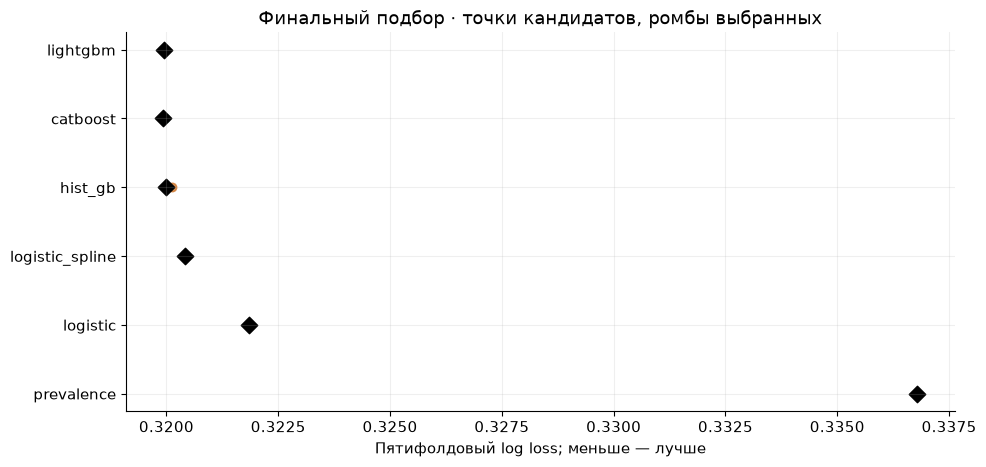

,model,artifact
0,catboost,/Users/nick/Desktop/projects/femfedora/models/...
1,hist_gb,/Users/nick/Desktop/projects/femfedora/models/...
2,lightgbm,/Users/nick/Desktop/projects/femfedora/models/...
3,logistic,/Users/nick/Desktop/projects/femfedora/models/...
4,logistic_spline,/Users/nick/Desktop/projects/femfedora/models/...
5,prevalence,/Users/nick/Desktop/projects/femfedora/models/...


In [16]:
final_best = load_full_cohort_best()
final_summary = pd.read_csv(FINAL_DIR / "candidate_summary.csv", dtype={"candidate_id": str})
assert final_best["development_n"] == len(oof_nested)
assert final_best["development_events"] == int(oof_nested.label.sum())
print("Итоговый победитель:", final_best["overall_winner"])
display(final_summary.round(5))
display(pd.DataFrame(final_best["best_by_model"]).T)
final_selected = final_summary.loc[final_summary.apply(
    lambda row: row.candidate_id == final_best["best_by_model"][row.model]["candidate_id"], axis=1)]
fig, ax = plt.subplots(figsize=(10, 4.8))
for name in MODEL_NAMES:
    part = final_summary.loc[final_summary.model.eq(name)]
    ax.scatter(part.cv_log_loss, np.repeat(name, len(part)), color=palette[name], alpha=.55)
    chosen = final_selected.loc[final_selected.model.eq(name)].iloc[0]
    ax.scatter(chosen.cv_log_loss, name, color="black", marker="D", s=70)
ax.set(xlabel="Пятифолдовый log loss; меньше — лучше", title="Финальный подбор · точки кандидатов, ромбы выбранных")
plt.tight_layout(); plt.show()
global_manifest = json.loads((ROOT / "models/exported/preeclampsia_cdc/global_full_cv_2023_2024.json").read_text())
assert global_manifest["overall_winner"] == final_best["overall_winner"]
display(pd.DataFrame([{"model": name, "artifact": path} for name, path in global_manifest["artifacts"].items()]))

## Как читать результаты

Минимум `log loss` выбирает конфигурацию по качеству вероятностей в заданной сетке, но не исправляет ошибку регистрации HDP-proxy. Частота и полнота кодирования гестационной гипертензии/преэклампсии, уже существовавшая профилактика, отсутствие ID женщины и факт просмотра 2024 ограничивают клинический вывод. Если преимущество сложной модели мало, опирайтесь на калибровку, перенос и простоту — не на десятые доли процента AUROC. Следующая честная проверка общей модели требует нового периода или независимого клинического набора с подтверждёнными диагнозами.